# Objetivo del análisis

**Pregunta de negocio:** ¿Qué categorías, subcategorías/productos y regiones generan o destruyen rentabilidad, y en qué segmentos de descuento conviene investigar las pérdidas?

Para responderla, compararemos ventas y ganancias agregadas por categoría, subcategoría, producto, región y estado. Revisaremos las ganancias y los márgenes según los valores de descuento observados, buscando patrones que indiquen dónde profundizar.

- El margen agregado se calculará como ganancia total dividida entre ventas totales; no se promediarán los márgenes por fila.
- Empezaremos por los valores de descuento presentes en el dataset, sin agruparlos en intervalos arbitrarios.
- El análisis identifica asociaciones descriptivas, no prueba que los descuentos causen pérdidas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "../data/raw/Sample - Superstore.csv",
    encoding="latin1"
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [4]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [6]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
df.isna().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [8]:
duplicate_rows = df[df.duplicated()]
duplicate_rows

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [9]:
df['profit_margin'] = df['Profit'] / df['Sales']

df['year'] = df['Order Date'].dt.year
df['month'] = df['Order Date'].dt.month
df['day_of_week'] = df['Order Date'].dt.day_name()

In [10]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,profit_margin,year,month,day_of_week
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,0.1600,2016,11,Tuesday
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,0.3000,2016,11,Tuesday
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,0.4700,2016,6,Sunday
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-0.4000,2015,10,Sunday
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,0.1125,2015,10,Sunday


## Análisis de ventas por categoría y subcategoría

In [11]:
# ¿Cuál categoria genera más ingresos?
sales_category = (df.groupby('Category')['Sales'].sum().sort_values(ascending=False))
print (sales_category)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [12]:
# Ver ganancias por categoría
profit_category = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)
print(profit_category)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [13]:
# Comparar ventas y ganancias juntas
category_analysis = (
    df.groupby("Category").agg({"Sales":"sum","Profit":"sum","Quantity":"sum","Discount":"mean"})
)

print(category_analysis)

                       Sales       Profit  Quantity  Discount
Category                                                     
Furniture        741999.7953   18451.2728      8028  0.173923
Office Supplies  719047.0320  122490.8008     22906  0.157285
Technology       836154.0330  145454.9481      6939  0.132323


In [14]:
sub_analysis = (
    df.groupby(["Category","Sub-Category"])
    .agg({
        "Sales":"sum",
        "Profit":"sum",
        "Quantity":"sum"
    }).sort_values("Sales", ascending=False)
)

print(sub_analysis)

                                    Sales      Profit  Quantity
Category        Sub-Category                                   
Technology      Phones        330007.0540  44515.7306      3289
Furniture       Chairs        328449.1030  26590.1663      2356
Office Supplies Storage       223843.6080  21278.8264      3158
Furniture       Tables        206965.5320 -17725.4811      1241
Office Supplies Binders       203412.7330  30221.7633      5974
Technology      Machines      189238.6310   3384.7569       440
                Accessories   167380.3180  41936.6357      2976
                Copiers       149528.0300  55617.8249       234
Furniture       Bookcases     114879.9963  -3472.5560       868
Office Supplies Appliances    107532.1610  18138.0054      1729
Furniture       Furnishings    91705.1640  13059.1436      3563
Office Supplies Paper          78479.2060  34053.5693      5178
                Supplies       46673.5380  -1189.0995       647
                Art            27118.792

In [15]:
# ¿Quién vende mucho pero pierde dinero?
loss_products = (
    df
    .groupby("Sub-Category")
    .agg({
        "Sales":"sum",
        "Profit":"sum"
    })
)

loss_products = loss_products.query("Profit < 0")

print(loss_products)

                    Sales      Profit
Sub-Category                         
Bookcases     114879.9963  -3472.5560
Supplies       46673.5380  -1189.0995
Tables        206965.5320 -17725.4811


In [16]:
discount_analysis = (df.groupby("Sub-Category")
    .agg({
        "Discount":"mean",
        "Profit":"sum"
    })
)
print(discount_analysis)

              Discount      Profit
Sub-Category                      
Accessories   0.078452  41936.6357
Appliances    0.166524  18138.0054
Art           0.074874   6527.7870
Binders       0.372292  30221.7633
Bookcases     0.211140  -3472.5560
Chairs        0.170178  26590.1663
Copiers       0.161765  55617.8249
Envelopes     0.080315   6964.1767
Fasteners     0.082028    949.5182
Furnishings   0.138349  13059.1436
Labels        0.068681   5546.2540
Machines      0.306087   3384.7569
Paper         0.074891  34053.5693
Phones        0.154556  44515.7306
Storage       0.074704  21278.8264
Supplies      0.076842  -1189.0995
Tables        0.261285 -17725.4811


<Axes: xlabel='Category'>

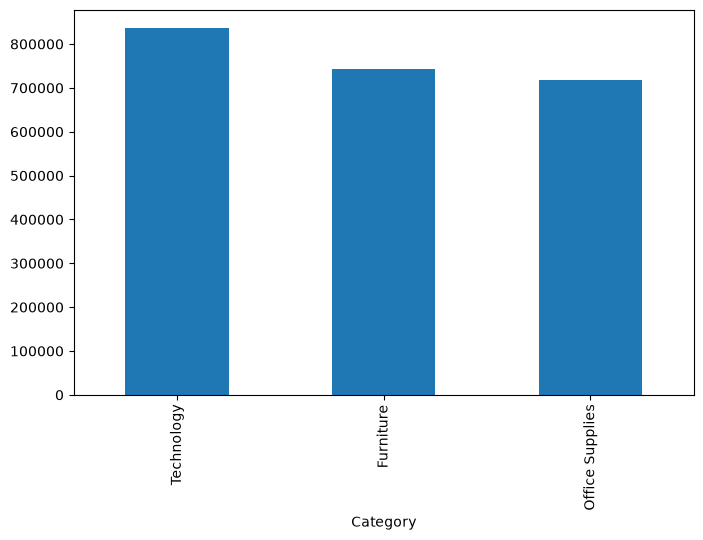

In [17]:
sales_category.plot(
    kind="bar",
    figsize=(8,5)
)

## Análisis de rentabilidad por región y estado

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [19]:
# ¿Qué región genera más ventas?
sales_region = (df.groupby("Region")["Sales"].sum().sort_values(ascending=False))
print(sales_region)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [20]:
# ¿Qué región genera mayor ganancia?
profit_region = (df.groupby("Region")["Profit"].sum().sort_values(ascending=False))
print(profit_region)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


In [21]:
# ¿Qué región tiene mejor margen de rentabilidad?
region_analysis = (df.groupby("Region").agg({"Sales":"sum", "Profit":"sum"}))
print(region_analysis)

               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


In [22]:
# ¿Qué estados aportan más utilidad total?
profit_state = (df.groupby("State")["Profit"].sum().sort_values(ascending=False))
print(profit_state)

State
California              76381.3871
New York                74038.5486
Washington              33402.6517
Michigan                24463.1876
Virginia                18597.9504
Indiana                 18382.9363
Georgia                 16250.0433
Kentucky                11199.6966
Minnesota               10823.1874
Delaware                 9977.3748
New Jersey               9772.9138
Wisconsin                8401.8004
Rhode Island             7285.6293
Maryland                 7031.1788
Massachusetts            6785.5016
Missouri                 6436.2105
Alabama                  5786.8253
Oklahoma                 4853.9560
Arkansas                 4008.6871
Connecticut              3511.4918
Nevada                   3316.7659
Mississippi              3172.9762
Utah                     2546.5335
Vermont                  2244.9783
Louisiana                2196.1023
Nebraska                 2037.0942
Montana                  1833.3285
South Carolina           1769.0566
New Hampshire 

In [23]:
# ¿Qué estados tienen pérdidas?
loss_state = (df.groupby("State").agg({"Sales":"sum",
       "Profit":"sum"}))

loss_state = loss_state.query("Profit < 0")
print(loss_state)

                      Sales      Profit
State                                  
Arizona          35282.0010  -3427.9246
Colorado         32108.1180  -6527.8579
Florida          89473.7080  -3399.3017
Illinois         80166.1010 -12607.8870
North Carolina   55603.1640  -7490.9122
Ohio             78258.1360 -16971.3766
Oregon           17431.1500  -1190.4705
Pennsylvania    116511.9140 -15559.9603
Tennessee        30661.8730  -5341.6936
Texas           170188.0458 -25729.3563


In [24]:
# ¿Los descuentos afectan la rentabilidad por estado?
state_discount_analysis = (df.groupby("State").agg({"Discount":"mean", "Profit":"sum"}))
print(state_discount_analysis)

                      Discount      Profit
State                                     
Alabama               0.000000   5786.8253
Arizona               0.303571  -3427.9246
Arkansas              0.000000   4008.6871
California            0.072764  76381.3871
Colorado              0.316484  -6527.8579
Connecticut           0.007317   3511.4918
Delaware              0.006250   9977.3748
District of Columbia  0.000000   1059.5893
Florida               0.299347  -3399.3017
Georgia               0.000000  16250.0433
Idaho                 0.085714    826.7231
Illinois              0.390041 -12607.8870
Indiana               0.000000  18382.9363
Iowa                  0.000000   1183.8119
Kansas                0.000000    836.4435
Kentucky              0.000000  11199.6966
Louisiana             0.000000   2196.1023
Maine                 0.000000    454.4862
Maryland              0.005714   7031.1788
Massachusetts         0.015556   6785.5016
Michigan              0.007059  24463.1876
Minnesota  

In [25]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,profit_margin,year,month
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896,0.120314,2015.722233,7.809686
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,-2.750000,2014.000000,1.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,0.075000,2015.000000,5.000000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,0.270000,2016.000000,9.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,0.362500,2017.000000,11.000000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,0.500000,2017.000000,12.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,0.466754,1.123555,3.284654
